# Unsupervised Learning Capstone Challenge

This project is an end-to-end Unsupervised Learning building solution for real transaction data.

Online Retail Data Analysis, Customer Segmentation, Market Basket Analysis, and Recommendation Systems.

## Part 1 — Business Understanding & Data Exploration

- The company wants to discover groups of customers that purchased or choose their products, based on the behavior of each customer or group, to keep loyal customer, and encourage others by offering, advertising stategies,.. 
plus, it wants to discover the relation between products, the association, to make collection, baskets, offers, and recommend products.. 
and improve the experience.  

- Choosing learning model :   
Unsupervised learning is suitable with this problem because the company doen't know a predifined values of clusters and segmetns, the model analyse customers behavior and automatically suggest the best number of cluster and regroup data.  
- Clustering supports marketing desicions, need of offering, advertising, rerouping products, recommending, also can lead to redesign the web page to enhance the experience of choosing and viewing products. 


- About the dataset : 
This dataset contains real transactions from a UK-based online gift store.
Period:
December 2010 → December 2011
Approximately:
541,000 transactions

#### 1. Import Libraries : 

In [168]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import openpyxl
import seaborn as sns

# from scipy.sparse import csr_matrix
# from sklearn.neighbors import NearestNeighbors
# from sklearn.metrics.pairwise import cosine_similarity

#### 2. Load Dataset

In [170]:
retail_data = pd.read_excel("../Assigment-challenges/online_retail.xlsx", engine="openpyxl")
retail_data.to_csv("online_retail_original.csv", index=False, encoding="utf-8-sig")

In [171]:
retail_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [197]:
df = retail_data.copy()

In [198]:
print(df.shape) 
print("------")
print(df.dtypes)
print("------")
print(df.info())


(541909, 8)
------
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object
------
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB
None


## Part 2 — Data Cleaning & Feature Engineering

In [199]:
#percentage of missing values 
missing_count = df.isnull().value_counts() /len(df) *100
missing_count

InvoiceNo  StockCode  Description  Quantity  InvoiceDate  UnitPrice  CustomerID  Country
False      False      False        False     False        False      False       False      75.073306
                                                                     True        False      24.658384
                      True         False     False        False      True        False       0.268311
Name: count, dtype: float64

In [200]:
#nb of duplicated rows
df.duplicated().sum()

np.int64(5268)

In [201]:
#remove duplicates :
df = df.drop_duplicates()
print(df.shape)

(536641, 8)


In [202]:
#nb of unique values in each columns 
nunique = pd.DataFrame(df.nunique(), columns=["#_of_Unique"])
nunique

,#_of_Unique
InvoiceNo,25900
StockCode,4070
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


In [203]:
print(f"{df['UnitPrice'].min()}, {df['UnitPrice'].max()}")  

-11062.06, 38970.0


In [204]:
print(f"{df['Quantity'].min()}, {df['Quantity'].max()}") 

-80995, 80995


In [205]:
#create new columns
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']


In [206]:
#sort by ascending order, price by country 
df.groupby("Country").agg({"TotalPrice":"sum"}).sort_values("TotalPrice", ascending = False).head()

,TotalPrice
Country,
United Kingdom,8167128.184
Netherlands,284661.540
EIRE,262993.380
Germany,221509.470
France,197317.110


In [208]:
#create new column about transcation type to avoid the negative value of totalprice 
df['transactiontype'] = df['TotalPrice'].apply(lambda x: "Return" if x <0 else "Purchase")

In [231]:
print(df['Description'].isna().sum())

1454


In [232]:
df = df.dropna(subset=['Description'])

In [233]:
df.isna().sum()

InvoiceNo               0
StockCode               0
Description             0
Quantity                0
InvoiceDate             0
UnitPrice               0
CustomerID         133583
Country                 0
TotalPrice              0
transactiontype         0
dtype: int64

In [234]:
#find different products : 
df['Description'].unique()

array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ..., 'lost',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], shape=(4223,), dtype=object)

In [243]:
df = df.dropna(subset= 'CustomerID')

In [248]:
df.isna().sum()

InvoiceNo          0
StockCode          0
Description        0
Quantity           0
InvoiceDate        0
UnitPrice          0
CustomerID         0
Country            0
TotalPrice         0
transactiontype    0
dtype: int64

In [249]:
#canceled recodrs start e=with C 
#sum of regulaer and cancellation sum

df["InvoiceNo"] = df["InvoiceNo"].astype("string")
regular_invoices = df[~df['InvoiceNo'].str.startswith('C')]
canceled_invoices = df[df['InvoiceNo'].str.startswith('C')]

canceled_invoices.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,transactiontype
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50,Return
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65,Return
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80,Return
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96,Return
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96,Return


In [250]:
regular_sum = regular_invoices['TotalPrice'].sum()
canceled_sum = canceled_invoices['TotalPrice'].sum()

print("Total Sales for Regular Invoices:", regular_sum)
print("Total Sales for Canceled Invoices:", canceled_sum)

Total Sales for Regular Invoices: 8887208.894
Total Sales for Canceled Invoices: -608689.47


In [252]:
#percentage of regular and canceled transactions
per_regular = len(regular_invoices)/ len(df) *100
per_regular

97.79085865678628

In [254]:
can_regular = len(canceled_invoices)/ len(df) *100
can_regular

2.209141343213713

In [251]:
print(df.shape)

(401604, 10)


### 4. Visualize data

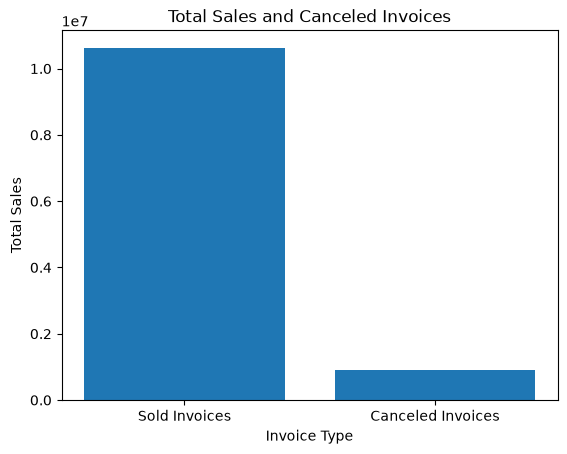

In [237]:
plt.bar(['Sold Invoices', 'Canceled Invoices'], [regular_sum, canceled_sum*-1])
plt.xlabel('Invoice Type')
plt.ylabel('Total Sales')
plt.title('Total Sales and Canceled Invoices')
plt.show()

Completed invoices are more then canceled invoices 

we show the head of the dataset, shape, info,..   
this dataset contains many null values(~75% of customerId and ~25% of  description), many duplicated values (remove it),we deleted it.  
create new feature (total price = unitprice * quantity), we have some negative values in price and quantity columns according of returned and canceled transaction.
we have transactions from 38  different countries,  United Kingdom reach the highest totalprice and 4223 different products.  
97% of transactions are comleted, 3% of transactions are returned.

'next notebook i drop incompleted transactions.'